In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/cars_features.csv')

In [ ]:
df.shape

(3981, 21)

In [ ]:
df.dtypes

,0
model_year,int64
milage,int64
price,float64
horsepower,float64
engine_size,float64
brand_encoded,int64
accident_encoded,int64
clean_title_encoded,int64
engine_type_encoded,int64
fuel_type_Diesel,int64


In [ ]:
df.isnull().sum()

,0
model_year,0
milage,0
price,0
horsepower,0
engine_size,0
brand_encoded,0
accident_encoded,0
clean_title_encoded,0
engine_type_encoded,0
fuel_type_Diesel,0


<div dir="ltr">

### Dataset Loading

The dataset contains 3,981 rows and 21 columns. All columns are numeric, and no text columns remain. There are also no missing values in the dataset. This result indicates that the Phase 3 steps, including encoding text columns, filling missing values, and converting Boolean columns to zeros and ones, have been correctly applied to the saved file. Therefore, the dataset is structurally ready to be fed into the model.

</div>

In [ ]:
[c for c in ['model', 'ext_col', 'int_col'] if c in df.columns]

[]

In [ ]:
df = df.drop(columns=['model', 'ext_col', 'int_col'], errors='ignore')

In [ ]:
df.shape

(3981, 21)

<div dir="ltr">

### Reviewing the Remaining Text Columns

**Can these columns be used directly in the model?**

No. These three columns contain text, and linear regression models work only with numerical values.

**What methods are available to handle them?**

The available methods include dropping the columns, One-Hot Encoding, Label Encoding, and grouping infrequent categories into an "Other" category. One-Hot Encoding would have created more than 2,300 new columns. Label Encoding also introduces a meaningless numerical order, which can be misleading for a linear model.

**What decision was made in this project?**

These columns were dropped because the number of categories is comparable to the number of rows in the dataset, and most models appear only once or twice. Therefore, the model cannot learn meaningful patterns from them. Removing the model name may slightly reduce accuracy because some of its price-related information is lost. The decision to drop these columns was made in Phase 3 and was confirmed through further examination in this phase.

</div>

In [ ]:
target = 'price'

X = df.drop(columns=[target])
y = df[target]

In [ ]:
X.shape

(3981, 20)

In [ ]:
y.shape

(3981,)

In [ ]:
'price' in X.columns

False

In [ ]:
X.isnull() .sum() .sum()

np.int64(0)

<div dir="ltr">

### Feature Selection and Target Column

The target column in this project is the price, since the goal is to predict car prices. The price column was separated from the other columns and stored in a separate variable, `y`, while the remaining twenty columns were assigned to the variable `X` as input features. The dimensions of `X` are 3,981 rows and 20 columns, while `y` contains 3,981 values.

It was verified that the price column was not included among the features, since otherwise the model would already have access to the correct answer. There are also no missing values in the features, so there was no need for median imputation. A second check confirmed the same result.

</div>

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
X_train.shape

(3184, 20)

In [ ]:
X_test.shape

(797, 20)

In [ ]:
y_train.shape

(3184,)

In [ ]:
y_test.shape

(797,)

<div dir="ltr">

### Splitting the Data into Training and Testing Sets

The data was split into two sets using an 80:20 ratio. The training set contains 3,184 rows and 20 columns, while the testing set contains 797 rows and 20 columns. The target column was split using the same ratio.

The reason for this split is that the model must be evaluated on cars it has not seen during training. If the model is trained on all the data and tested on the same data, it may simply have memorized the data, making it impossible to determine its actual performance. To ensure reproducibility, a fixed random seed was used for the split so that the same division is obtained every time the code is executed.

</div>

In [ ]:
num_cols = ['model_year', 'milage', 'horsepower', 'engine_size']

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])

X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

In [ ]:
X_train_scaled[num_cols].describe().loc[['mean', 'std']]

,model_year,milage,horsepower,engine_size
mean,9.238841e-16,8.480095e-17,-6.694812e-17,-3.124246e-17
std,1.000157e+00,1.000157e+00,1.000157e+00,1.000157e+00


In [ ]:
X_test_scaled[num_cols].describe().loc[['mean', 'std']]

,model_year,milage,horsepower,engine_size
mean,-0.111162,0.076435,-0.007645,0.059734
std,1.047297,1.047417,1.032102,1.014491


<div dir="ltr">

### Feature Standardization

The four continuous features, namely manufacturing year, mileage, engine horsepower, and engine size, were standardized using the `StandardScaler` method. The One-Hot columns, which already contain zeros and ones, and the Label-Encoded columns, which represent category codes, were left unchanged because their numerical values do not have a quantitative meaning. The scaler was fitted only on the training data, and the same scaler was then applied to the testing data.

The results showed that, in the training data, the mean of each column was approximately zero and the standard deviation was around one. In the testing data, these values were close to zero and one, but not exactly equal, indicating that the scaler had not learned any information from the testing data.

**Why shouldn't the scaler be fitted on the entire dataset?**

If the mean and standard deviation are calculated using the entire dataset, information from the testing data enters the training process before evaluation. This problem is known as data leakage and can make the evaluation results more optimistic than the model's actual performance. The testing data should simulate unseen cars, so no statistics from it should influence the training process.

</div>

In [ ]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'coefficient': model.coef_
}).sort_values('coefficient', ascending=False)

coef_df

,feature,coefficient
8,fuel_type_Diesel,11625.594146
2,horsepower,10860.780158
14,fuel_type_–,7458.346235
0,model_year,6770.697159
11,fuel_type_Hybrid,6311.680170
5,accident_encoded,4911.707043
18,transmission_clean_Manual,4716.026846
3,engine_size,3513.326175
17,transmission_clean_Dual Shift,2727.106119
19,transmission_clean_Other,1062.159730


In [ ]:
model.intercept_

np.float64(39625.034236991545)

<div dir="ltr">

### Training the Linear Regression Model

A linear regression model was created and trained using the training data. The model learned one coefficient for each of the twenty features, along with an intercept. The model's intercept is approximately $39,625.

Among the continuous features, engine horsepower has the strongest positive effect, with a coefficient of approximately 10,860, while mileage has the strongest negative effect, with a coefficient of approximately -11,000. Manufacturing year also has a positive coefficient. These directions are consistent with the analyses from Phases 1 and 3: more powerful and newer cars tend to be more expensive, while cars with higher mileage tend to be cheaper. Since these four features were standardized, their coefficients represent the change in price associated with a one-standard-deviation increase in each feature, making them comparable with one another.

There are several limitations when interpreting the coefficients. The coefficients of the One-Hot columns for fuel type and transmission cannot be interpreted independently, because only the differences between coefficients within each group are meaningful. The coefficients of Label-Encoded columns, such as brand, are close to zero because the codes assigned to these columns only represent the alphabetical order of the categories and have no linear relationship with price. This indicates that the model has made limited use of brand information.

</div>

In [ ]:
y_pred = model.predict(X_test_scaled)

In [ ]:
results = pd.DataFrame({
    'actual': y_test.values,
    'predicted': y_pred
})
results['difference'] = results['actual'] - results['predicted']

results.round(0).head(10)

,actual,predicted,difference
0,35345.0,45077.0,-9732.0
1,15000.0,27326.0,-12326.0
2,10900.0,1724.0,9176.0
3,21900.0,25861.0,-3961.0
4,134000.0,75997.0,58003.0
5,49995.0,38970.0,11025.0
6,18500.0,9355.0,9145.0
7,7000.0,25281.0,-18281.0
8,42995.0,43846.0,-851.0
9,91000.0,83607.0,7393.0


<div dir="ltr">

### Predicting Car Prices

The prices of 797 cars in the test set were predicted, and the first ten predictions were compared with the actual prices. The difference column is calculated as the actual price minus the predicted price. A positive value means the model underestimated the price, while a negative value means it overestimated the price.

The model's performance across these ten samples is inconsistent. For one car with an actual price of approximately 43,000 USD, the difference was less than 1,000 USD. In contrast, for a car with an actual price of 134,000 USD, the model predicted approximately 76,000 USD, resulting in an error of about 58,000 USD. Larger errors are more common among expensive cars, and one possible reason is that the model has made limited use of brand information. For one car, the predicted price was also close to zero because linear regression does not impose a lower bound on its output.

Ten samples are not enough to judge the model as a whole. A more accurate evaluation using error metrics across all 797 test cars will be performed in the next task.

</div>

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

In [ ]:
metrics = pd.DataFrame({
    'metric': ['MAE', 'MSE', 'RMSE', 'R2'],
    'value': [mae, mse, rmse, r2]
})
metrics

,metric,value
0,MAE,1.655057e+04
1,MSE,8.424513e+08
2,RMSE,2.902501e+04
3,R2,4.437526e-01


In [ ]:
print("Mean price:", y_test.mean())
print("Median price:", y_test.median())

Mean price: 39873.15307402761
Median price: 29000.0


<div dir="ltr">

### Model Evaluation

The model was evaluated on 797 cars in the test set. The mean absolute error (MAE) was approximately 16,550 USD, the root mean squared error (RMSE) was approximately 29,000 USD, and the coefficient of determination (R²) was approximately 0.44. The average price of the test cars is approximately 39,900 USD, so the mean absolute error is about 41% of the average price. The coefficient of determination indicates that the model explains approximately 44% of the variation in car prices, while the remaining variation is unexplained. The fact that the root mean squared error is significantly larger than the mean absolute error indicates the presence of several very large errors, particularly for expensive cars.

**Does the model have acceptable performance?**

It is acceptable as a first baseline model because it has learned the correct direction of the relationships between the features and price, and the goal of this phase is to become familiar with the model training process. However, its accuracy is insufficient for real-world use because the average error is close to half the average price. Possible reasons for its poor performance include the nonlinear relationship between mileage and price, the limited use of brand information, the removal of the car model name, and the imputation of some missing engine horsepower values using the median. To improve performance, nonlinear models, better brand encoding, and a logarithmic transformation of the price could be used.

</div>

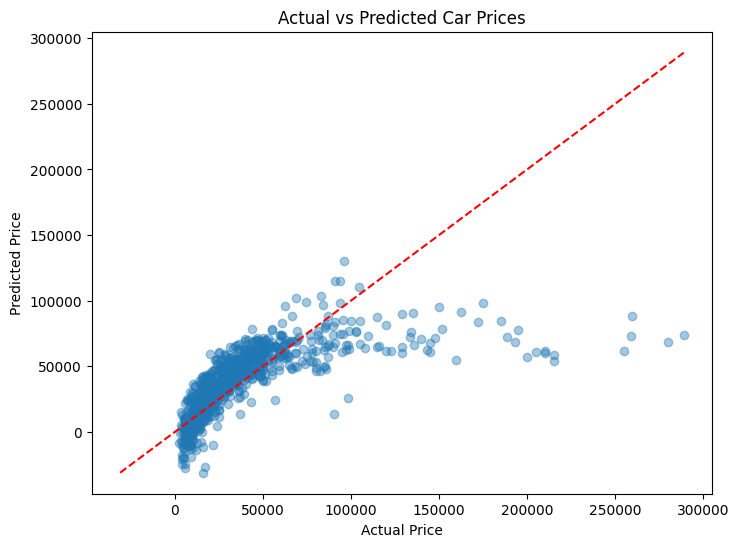

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Prices')
plt.show()

In [ ]:
os.makedirs('models', exist_ok=True)

joblib.dump(model, 'models/linear_regression.pkl')

['models/linear_regression.pkl']

In [ ]:
loaded_model = joblib.load('models/linear_regression.pkl')
np.allclose(loaded_model.predict(X_test_scaled), y_pred)

True